# Data Understanding, Preparation & Descriptive Modelling

**Goal.** Summarise and visualise the FinTx-Guard training set, answer a set of exploratory questions about what
distinguishes suspicious (`isFraud = 1`) from legitimate transactions, decide which clean-up / pre-processing steps are
needed, and use clustering to look for account-level behavioural profiles.

**Structure**
1. Setup & first look
2. Data quality audit (missing values, duplicates, ranges, consistency rules)
3. Target variable
4. Univariate distributions
5. Exploratory questions (Q1–Q7)
6. Descriptive modelling — clustering of sender accounts
7. Data cleaning & pre-processing pipeline
8. Summary of findings

## 1. Setup & first look

In [39]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.feature_selection import mutual_info_classif

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Consistent colours: blue = legitimate, orange = fraud, gray = reference lines
LEGIT, FRAUD, GRAY = "#2a78d6", "#eb6834", "#8a8984"
SEQ = "Blues"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "legend.frameon": False,
})
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("FinTx-Guard_train.csv")
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

100,459 rows x 19 columns


,transaction_id,time,date,sender_id,receiver_id,amount,payment_currency,received_currency,sender_bank_location,receiver_bank_location,payment_type,customer_session_duration,account_activity_score,transaction_channel,device_recognized,device_risk_score,verification_score,channel_flag,isFraud
0,76443,09:44:51,2023-04-19,AA49C7A57304F7CF25AFC3B34,A1B80787BB81A17BCF1093FEA,971.580,UK pounds,UK pounds,UK,UK,ACH,200,40.000,POS,0,-1.161,-1.272,0,0
1,13537,18:47:13,2022-11-11,AF929BA0C0E9FDF79640B04DB,AB88EA36C2764248B1083497E,56.000,UK pounds,UK pounds,UK,UK,ACH,308,62.300,Other,0,0.534,0.024,0,0
2,48424,03:00:23,2023-02-09,A1F5681C7C087BB287F571BF9,A77801AFFD4C07AA5C581067B,"7,079.230",UK pounds,UK pounds,UK,UK,Credit card,211,31.000,Other,1,0.393,1.409,0,0
3,77340,13:10:01,2023-04-21,AB298058402D02A7913DB3606,AB4371723703DB467AD2A1946,"25,042.780",UK pounds,UK pounds,UK,NaN,ACH,99,21.200,Other,1,0.934,-2.564,0,0
4,58679,16:16:50,2023-03-05,AECDF0440A068E3C82552C44C,A1CDD50184E01956054934B30,"4,580.900",Albanian lek,UK pounds,Albania,UK,Cross-border,85,29.800,Mobile App,1,0.219,2.443,0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100459 entries, 0 to 100458
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   transaction_id             100459 non-null  int64  
 1   time                       100459 non-null  str    
 2   date                       100459 non-null  str    
 3   sender_id                  100459 non-null  str    
 4   receiver_id                100459 non-null  str    
 5   amount                     97425 non-null   float64
 6   payment_currency           100459 non-null  str    
 7   received_currency          100459 non-null  str    
 8   sender_bank_location       95407 non-null   str    
 9   receiver_bank_location     92301 non-null   str    
 10  payment_type               94443 non-null   str    
 11  customer_session_duration  100459 non-null  int64  
 12  account_activity_score     90472 non-null   float64
 13  transaction_channel        96338 non-nul

The dataset has **100,459 transactions** and **19 columns**: one ID, two timestamp columns stored as text,
two anonymised account IDs, 1 monetary amount, 7 categorical attributes, 4 numeric behavioural scores, 2 binary flags and the target.

Groups of variables (following the data dictionary):

| Group | Columns |
|---|---|
| Identifiers | `transaction_id`, `sender_id`, `receiver_id` |
| Time | `date`, `time` |
| Monetary | `amount`, `payment_currency`, `received_currency` |
| Geography | `sender_bank_location`, `receiver_bank_location` |
| Transaction type / channel | `payment_type`, `transaction_channel`, `channel_flag` |
| Behavioural / device scores | `customer_session_duration`, `account_activity_score`, `device_recognized`, `device_risk_score`, `verification_score` |
| Target | `isFraud` |

In [4]:
NUM = ["amount", "customer_session_duration", "account_activity_score", "device_risk_score", "verification_score"]
CAT = ["payment_currency", "received_currency", "sender_bank_location", "receiver_bank_location",
       "payment_type", "transaction_channel"]
BIN = ["device_recognized", "channel_flag"]
TARGET = "isFraud"

df[NUM].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
amount,"97,425.000","11,171.769","110,502.473",6.430,64.484,"2,197.340","6,037.960","10,409.390","53,271.398","11,837,365.320"
customer_session_duration,"100,459.000",247.366,232.192,10.000,28.000,105.000,180.000,308.000,"1,161.000","3,600.000"
account_activity_score,"90,472.000",38.335,17.791,0.100,5.700,24.700,37.000,50.800,80.500,98.600
device_risk_score,"95,496.000",0.113,0.999,-4.799,-2.200,-0.562,0.115,0.791,2.430,4.500
verification_score,"100,459.000",-0.021,1.005,-4.404,-2.363,-0.694,-0.016,0.655,2.328,4.166


In [5]:
df[CAT + ["sender_id", "receiver_id", "date", "time"]].describe().T

,count,unique,top,freq
payment_currency,100459,13,UK pounds,95767
received_currency,100459,13,UK pounds,91205
sender_bank_location,95407,18,UK,92009
receiver_bank_location,92301,18,UK,84788
payment_type,94443,7,ACH,19453
transaction_channel,96338,4,Mobile App,43237
sender_id,100459,44595,A7CF757B9920DFC67F84DDDA0,30
receiver_id,100459,74648,A059EC0C0A685B7F6ABB20CCA,40
date,100459,256,2023-02-09,498
time,100459,54363,15:12:37,8


## 2. Data quality audit

### 2.1 Missing values

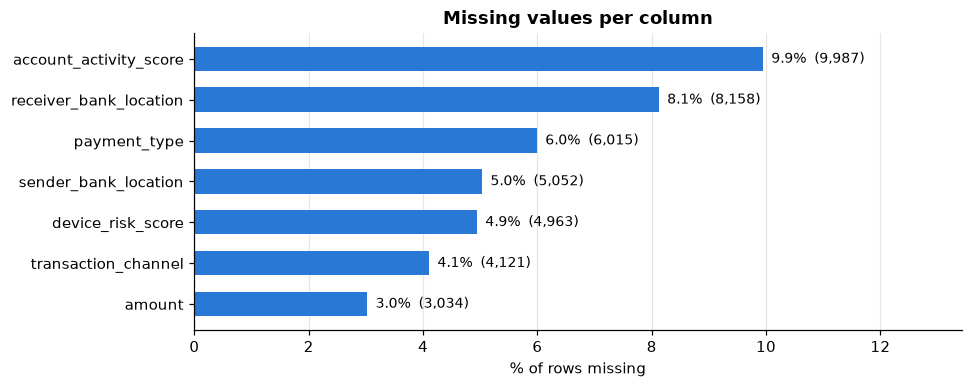

In [40]:
miss = (df.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(miss.index[::-1], miss.values[::-1], color=LEGIT, height=0.6)
for i, v in enumerate(miss.values[::-1]):
    ax.text(v + 0.15, i, f"{v:.1f}%  ({int(v / 100 * len(df)):,})", va="center", fontsize=9)
ax.set_xlabel("% of rows missing"); ax.set_title("Missing values per column")
ax.set_xlim(0, miss.max() * 1.35); ax.grid(axis="y", visible=False)
plt.show()

Seven columns have missing values (3–10% each). Before deciding how to impute, we check whether
missingness is **informative** — i.e. whether the fraud rate differs when the value is missing.

In [7]:
rows = []
for c in miss.index:
    m = df[c].isna()
    tab = pd.crosstab(m, df[TARGET])
    p = chi2_contingency(tab)[1]
    rows.append({"column": c, "n_missing": m.sum(),
                 "fraud_rate_missing": df.loc[m, TARGET].mean(),
                 "fraud_rate_present": df.loc[~m, TARGET].mean(), "chi2_p_value": p})
pd.DataFrame(rows).set_index("column")

,n_missing,fraud_rate_missing,fraud_rate_present,chi2_p_value
column,,,,
account_activity_score,9987,0.075,0.077,0.349
receiver_bank_location,8158,0.077,0.077,0.959
payment_type,6016,0.077,0.077,0.954
sender_bank_location,5052,0.083,0.077,0.138
device_risk_score,4963,0.077,0.077,0.925
transaction_channel,4121,0.073,0.077,0.314
amount,3034,0.087,0.077,0.033


Missingness is essentially **random with respect to fraud** (fraud rate ≈ 7.7% whether present or not). The only
borderline case is `amount` (8.7% vs 7.7%). Rows with missing values should therefore be **kept and imputed**, not dropped
(dropping every row with any missing value would discard ~35% of the data). A missing-indicator flag will be kept for
`amount` and the location columns as a precaution.

In [8]:
print("Rows with at least one missing value:", f"{df.isna().any(axis=1).mean():.1%}")

Rows with at least one missing value: 34.7%


### 2.2 Duplicates, identifiers and value ranges

In [9]:
print("Fully duplicated rows:            ", df.duplicated().sum())
print("Duplicated transaction_id:        ", df.transaction_id.duplicated().sum())
print("Duplicates ignoring transaction_id:", df.drop(columns="transaction_id").duplicated().sum())
print("Self-transfers (sender == receiver):", (df.sender_id == df.receiver_id).sum())
print("Non-positive amounts:             ", (df.amount <= 0).sum())
print("Unparseable times:                ", pd.to_datetime(df.time, format="%H:%M:%S", errors="coerce").isna().sum())
print("Unparseable dates:                ", pd.to_datetime(df.date, errors="coerce").isna().sum())
print("Date range:", df.date.min(), "->", df.date.max())
print("Session duration range (s):", df.customer_session_duration.min(), "-", df.customer_session_duration.max(),
      "| rows at the 3600 s cap:", (df.customer_session_duration == 3600).sum())
print(f"Unique senders: {df.sender_id.nunique():,} | unique receivers: {df.receiver_id.nunique():,} | "
      f"receivers that also send: {df.receiver_id.drop_duplicates().isin(df.sender_id).mean():.1%}")

Fully duplicated rows:             0
Duplicated transaction_id:         0
Duplicates ignoring transaction_id: 0
Self-transfers (sender == receiver): 0
Non-positive amounts:              0


Unparseable times:                 0
Unparseable dates:                 0
Date range: 2022-10-07 -> 2023-06-19
Session duration range (s): 10 - 3600 | rows at the 3600 s cap: 6


Unique senders: 44,595 | unique receivers: 74,648 | receivers that also send: 16.4%


No duplicates, no impossible values (negative amounts, malformed dates/times) and no self-transfers. The
`transaction_id` is a pure row identifier with no predictive meaning and will be dropped. `sender_id`/`receiver_id` are
high-cardinality and should **not** be one-hot encoded, but they are valuable for building account-level aggregates (Q6).

`amount` is extremely skewed: the median is ~6k but the maximum is ~11.8M (mean ≫ median), so a log transform is needed.
`customer_session_duration` looks right-capped at 3600 s (1 hour).

### 2.3 Consistency rules between columns

Several columns should be logically related: a bank's location should determine its currency, and a
`Cross-border` payment should have sender and receiver in different countries. Checking these rules tells us how
reliable the columns are and whether one can be used to **impute** the other.

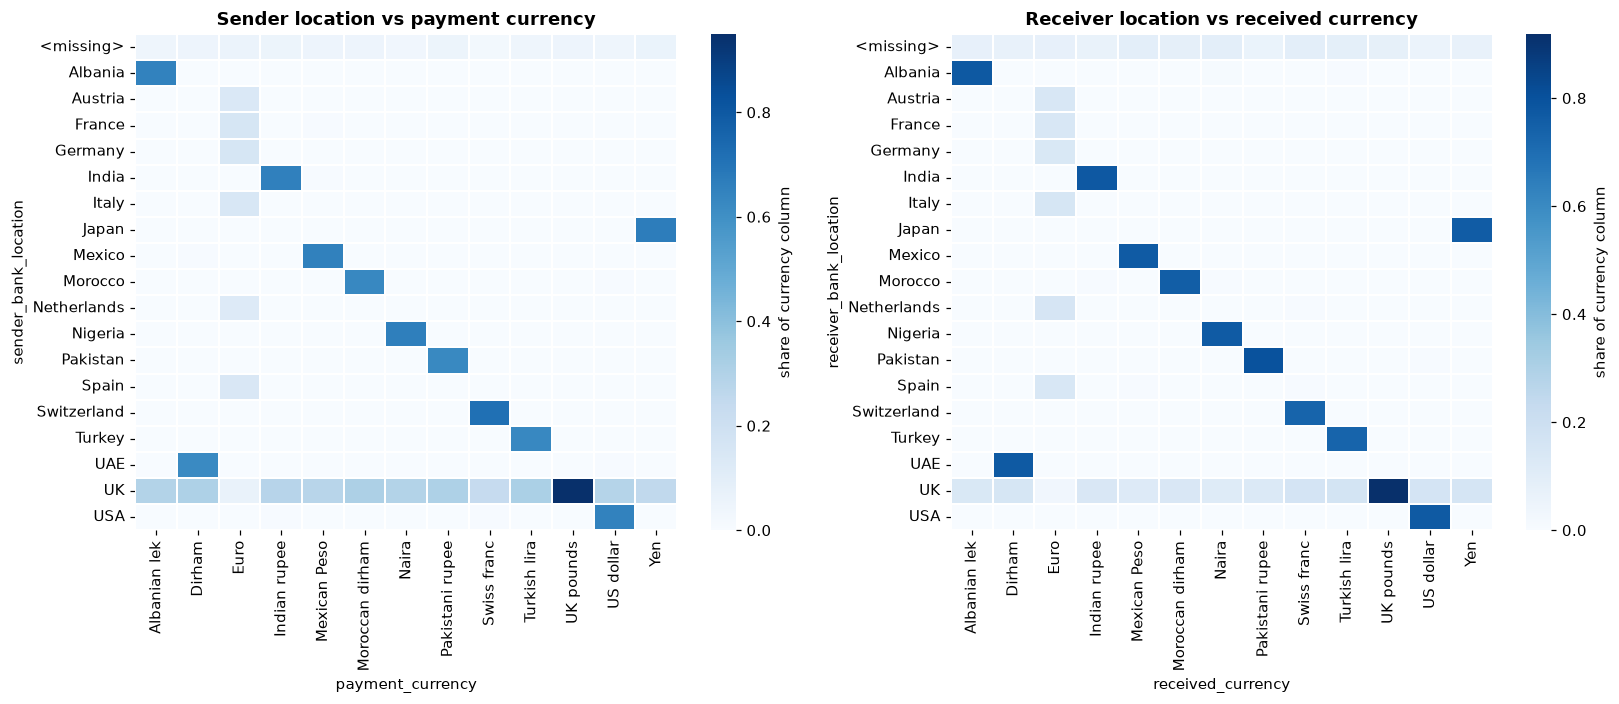

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, loc, cur, title in [(axes[0], "sender_bank_location", "payment_currency", "Sender location vs payment currency"),
                            (axes[1], "receiver_bank_location", "received_currency", "Receiver location vs received currency")]:
    ct = pd.crosstab(df[loc].fillna("<missing>"), df[cur])
    ct_norm = ct.div(ct.sum(axis=0), axis=1)            # share of each currency's rows per location
    sns.heatmap(ct_norm, cmap=SEQ, ax=ax, cbar_kws={"label": "share of currency column"}, linewidths=0.3)
    ax.set_title(title); ax.set_xlabel(cur); ax.set_ylabel(loc)
plt.tight_layout(); plt.show()

In [11]:
gbp_sender = df.loc[df.payment_currency == "UK pounds", "sender_bank_location"].value_counts(normalize=True, dropna=True)
gbp_recv = df.loc[df.received_currency == "UK pounds", "receiver_bank_location"].value_counts(normalize=True, dropna=True)
print(f"Sender rows paying in GBP with known location that are UK:   {gbp_sender.get('UK'):.2%}")
print(f"Receiver rows receiving GBP with known location that are UK: {gbp_recv.get('UK'):.2%}")
print("Missing sender location, by payment currency:")
print(df.loc[df.sender_bank_location.isna(), "payment_currency"].value_counts().head(4))

Sender rows paying in GBP with known location that are UK:   99.99%
Receiver rows receiving GBP with known location that are UK: 99.99%
Missing sender location, by payment currency:
payment_currency
UK pounds          4820
Euro                 74
Yen                  18
Pakistani rupee      18
Name: count, dtype: int64


* Currency and location are **almost deterministic**: every country uses its own currency (Euro shared by the
  Eurozone countries). The off-diagonal cells are UK banks transacting in foreign currencies (~100 rows per currency),
  which is plausible.
* **GBP ⇒ UK holds in >99.9% of rows**, and ~95% of missing locations are GBP rows. Missing locations can therefore be
  imputed as `UK` when the currency is GBP; the remainder (foreign currency) are ambiguous (a UK bank can also pay in
  a foreign currency) and become `Unknown`.

In [12]:
both_known = df.sender_bank_location.notna() & df.receiver_bank_location.notna()
df_chk = df[both_known].assign(diff_location=lambda d: d.sender_bank_location != d.receiver_bank_location,
                               diff_currency=lambda d: d.payment_currency != d.received_currency)
pd.concat([pd.crosstab(df_chk.payment_type.fillna("<missing>"), df_chk.diff_location).add_prefix("diff_location="),
           pd.crosstab(df_chk.payment_type.fillna("<missing>"), df_chk.diff_currency).add_prefix("diff_currency=")], axis=1)

,diff_location=False,diff_location=True,diff_currency=False,diff_currency=True
payment_type,,,,
<missing>,4706,565,4608,663
ACH,16984,0,16585,399
Cash Deposit,2642,0,2604,38
Cash Withdrawal,3037,259,3037,259
Cheque,16775,0,16354,421
Credit card,16762,0,16386,376
Cross-border,0,9109,53,9056
Debit card,16844,0,16437,407


* When both locations are known, **every** `Cross-border` payment is between two different countries, and **97%** of
  transactions between two different countries are `Cross-border` (the rest are cash withdrawals abroad). So for rows with **missing `payment_type`** where the two
  locations differ, `Cross-border` is a high-confidence imputation; the other missing types become `Unknown`.
* A small number of domestic card/ACH/cheque payments involve a currency conversion — a minor inconsistency, kept as is.

In [13]:
print("Median amount by payment currency:")
print(df.groupby("payment_currency").amount.median().round(0).sort_values().to_string())

Median amount by payment currency:
payment_currency
UK pounds         5,968.000
Turkish lira      6,883.000
Pakistani rupee   7,058.000
Naira             7,076.000
Indian rupee      7,290.000
Swiss franc       7,302.000
Yen               7,379.000
Moroccan dirham   7,429.000
Dirham            7,454.000
Albanian lek      7,489.000
Euro              7,559.000
US dollar         7,573.000
Mexican Peso      7,801.000


**Observation on `amount`.** The data dictionary says amounts are in the payment currency, but the medians are very
similar across currencies (≈6–8k for both pounds and yen; 1 GBP ≈ 180 JPY). Amounts therefore appear to be already on a
**common scale (likely GBP)**, so no currency conversion is applied.

In [14]:
ct = pd.crosstab(df.transaction_channel.fillna("<missing>"), df.channel_flag, normalize="index")
print("Share of channel_flag = 1 within each channel:")
print(ct[1].round(3).to_string())

Share of channel_flag = 1 within each channel:
transaction_channel
<missing>    0.136
Mobile App   0.128
Other        0.135
POS          0.126
Web          0.128


`channel_flag` is not a deterministic function of `transaction_channel` (≈13% in every channel), so it carries
independent information and cannot be used to impute the channel.

## 3. Target variable

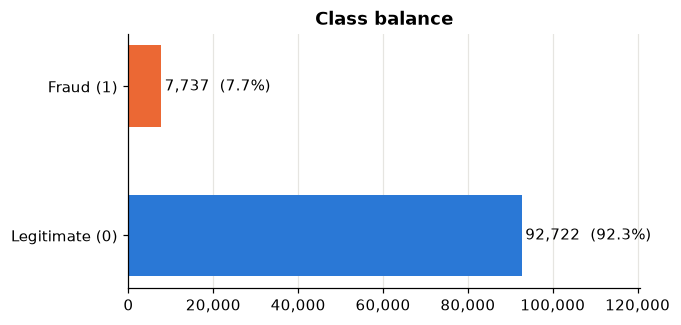

Base fraud rate: 7.70%  -> imbalance ratio ~ 1:12


In [15]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(["Legitimate (0)", "Fraud (1)"], counts.values, color=[LEGIT, FRAUD], height=0.55)
for i, v in enumerate(counts.values):
    ax.text(v + 800, i, f"{v:,}  ({v / counts.sum():.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.3); ax.set_title("Class balance"); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.show()
BASE_RATE = df[TARGET].mean()
print(f"Base fraud rate: {BASE_RATE:.2%}  -> imbalance ratio ~ 1:{(1 - BASE_RATE) / BASE_RATE:.0f}")

The target is **imbalanced (7.7% fraud, ~1:12)**. Consequences for later tasks: use stratified splits, prefer
precision/recall, F1 or PR-AUC over accuracy (a trivial "always legitimate" model has 92.3% accuracy), and consider
class weights or resampling. Throughout this notebook the dashed gray line in charts marks this base rate.

## 4. Univariate distributions

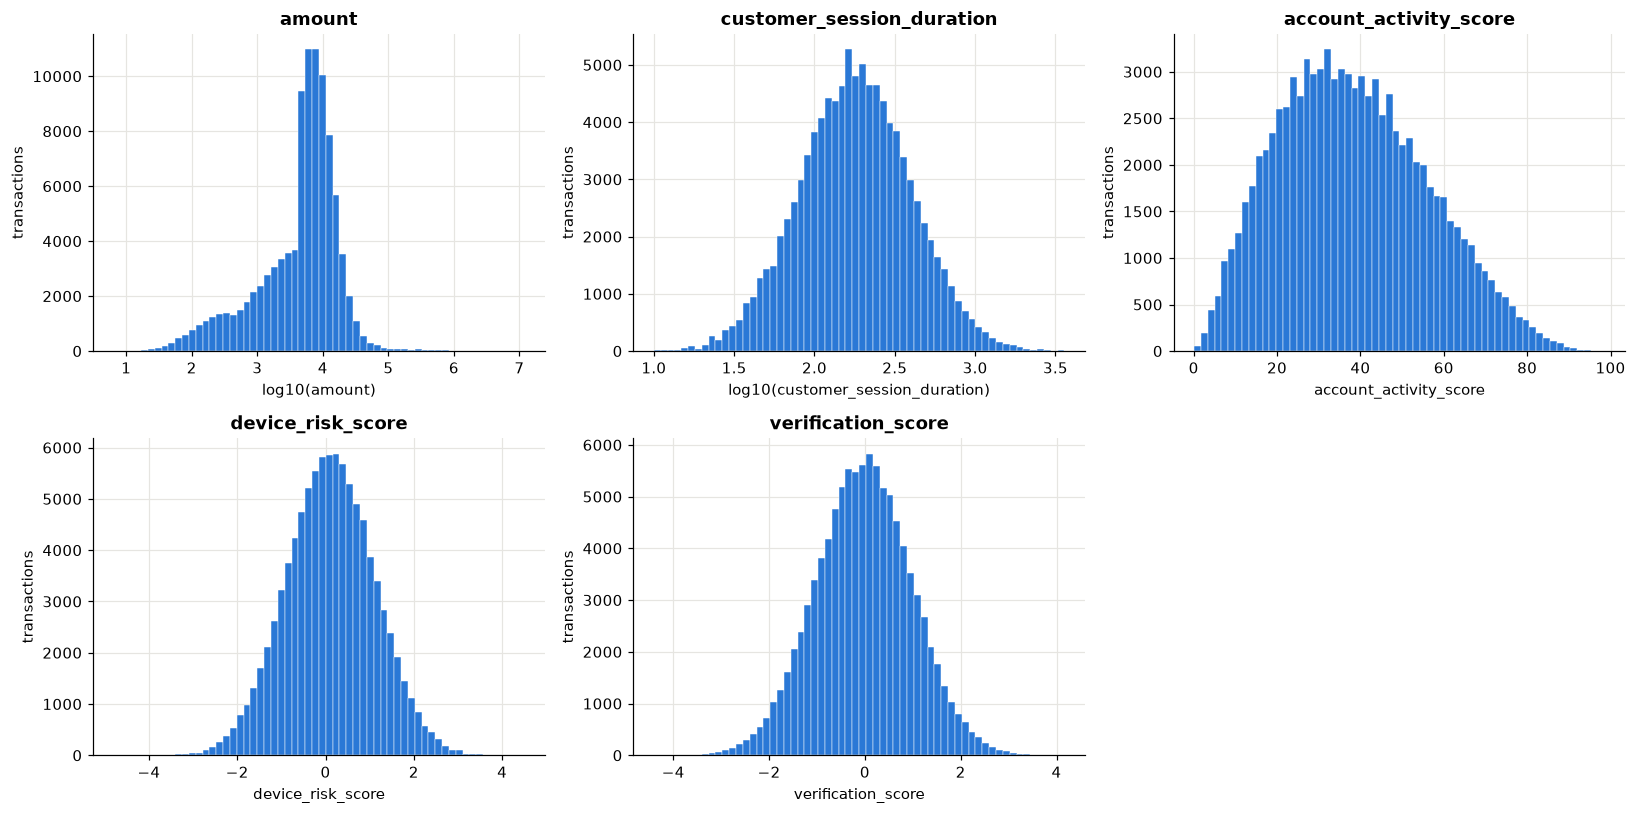

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
plot_cols = [("amount", True), ("customer_session_duration", True), ("account_activity_score", False),
             ("device_risk_score", False), ("verification_score", False)]
for ax, (c, logx) in zip(axes.flat, plot_cols):
    x = df[c].dropna()
    if logx:
        x = np.log10(x); ax.set_xlabel(f"log10({c})")
    else:
        ax.set_xlabel(c)
    ax.hist(x, bins=60, color=LEGIT, edgecolor="white", linewidth=0.3)
    ax.set_title(c); ax.set_ylabel("transactions")
axes.flat[-1].axis("off")
plt.tight_layout(); plt.show()

* `amount` is log-normal-like with a long right tail (a log scale is essential).
* `customer_session_duration` is right-skewed (median 3 min) with a hard cap at 3600 s.
* `account_activity_score` is bounded in (0, 100) and roughly bell-shaped.
* `device_risk_score` and `verification_score` look **already standardised** (mean ≈ 0, sd ≈ 1, near-Gaussian).

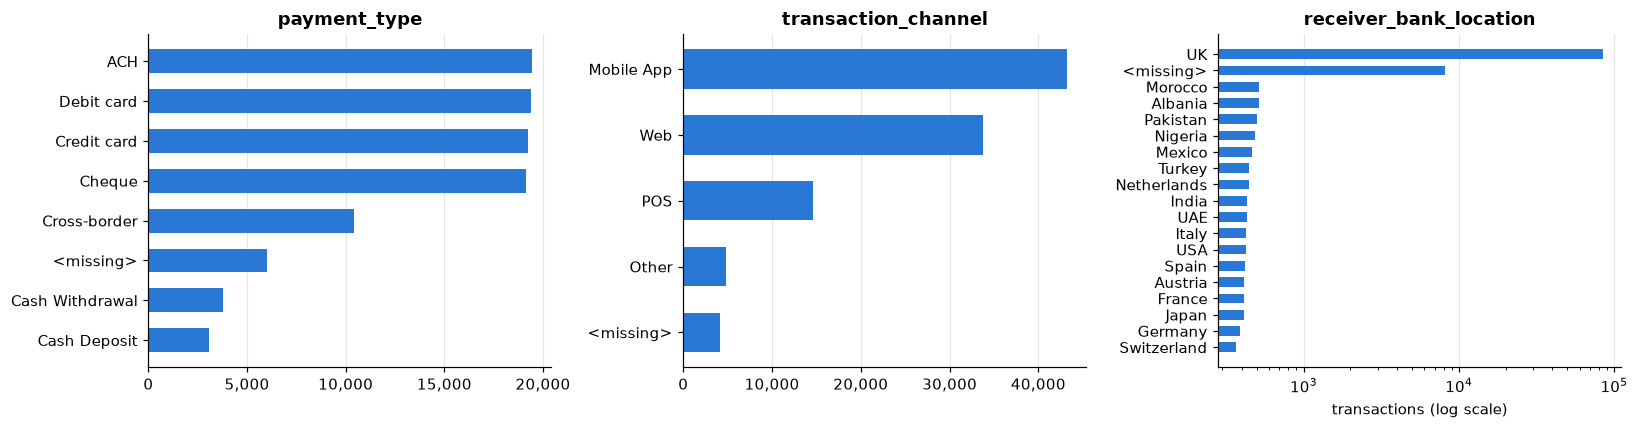

Share of transactions in GBP (payment): 95.3%; sender in UK: 91.6%


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["payment_type", "transaction_channel", "receiver_bank_location"]):
    vc = df[c].fillna("<missing>").value_counts()
    ax.barh(vc.index[::-1], vc.values[::-1], color=LEGIT, height=0.6)
    ax.set_title(c); ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    if c == "receiver_bank_location":
        ax.set_xscale("log"); ax.set_xlabel("transactions (log scale)")
plt.tight_layout(); plt.show()
print(f"Share of transactions in GBP (payment): {(df.payment_currency == 'UK pounds').mean():.1%}; "
      f"sender in UK: {(df.sender_bank_location == 'UK').mean():.1%}")

The data is dominated by **domestic UK activity** (95% paid in GBP, 92% UK senders). Card, ACH and cheque payments are
evenly represented (~19% each), followed by cross-border (10%) and cash operations (7%). Mobile app and web are the main
channels.

## 5. Exploratory questions

Helper: fraud rate per category with the number of transactions in each bar, against the global base rate.

In [18]:
def fraud_rate_plot(data, col, ax=None, top=None, title=None, min_n=0):
    g = data.groupby(data[col].astype(object).fillna("<missing>"), observed=True)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= min_n].sort_values("mean")
    if top: g = g.tail(top)
    ax = ax or plt.gca()
    colors = [FRAUD if m > BASE_RATE else LEGIT for m in g["mean"]]
    ax.barh(g.index.astype(str), g["mean"], color=colors, height=0.6)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.004, i, f"{m:.1%}  (n={n:,})", va="center", fontsize=8.5)
    ax.axvline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, g["mean"].max() * 1.4)
    ax.set_xlabel("fraud rate"); ax.set_title(title or f"Fraud rate by {col}"); ax.grid(axis="y", visible=False)
    return g

### Q1. Which payment types and channels are riskiest?

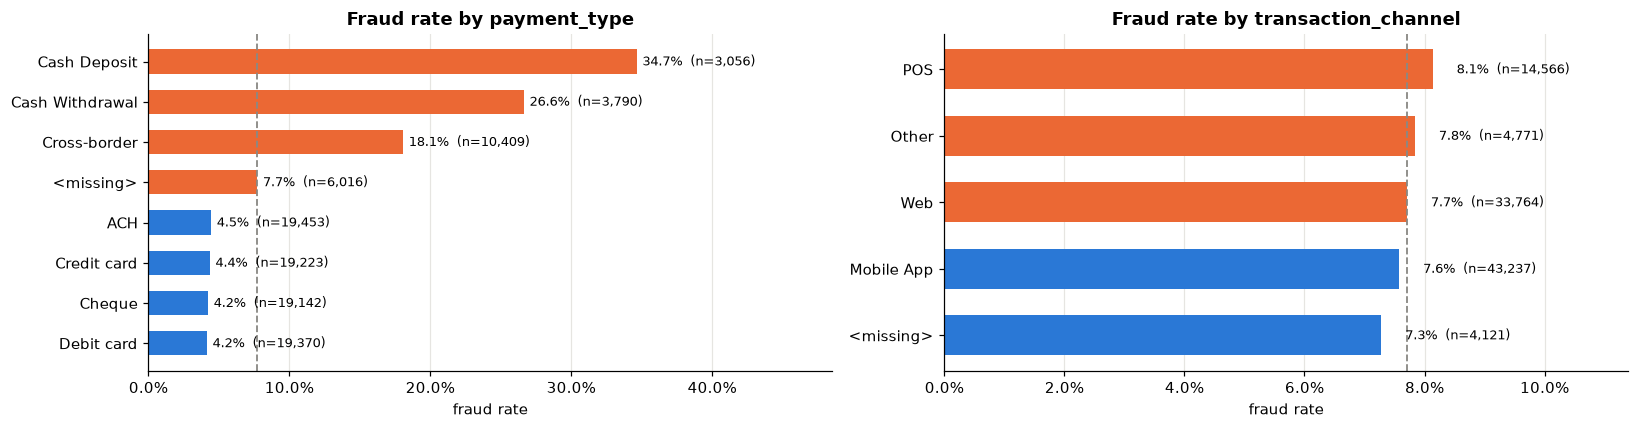

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
fraud_rate_plot(df, "payment_type", ax=axes[0])
fraud_rate_plot(df, "transaction_channel", ax=axes[1])
plt.tight_layout(); plt.show()

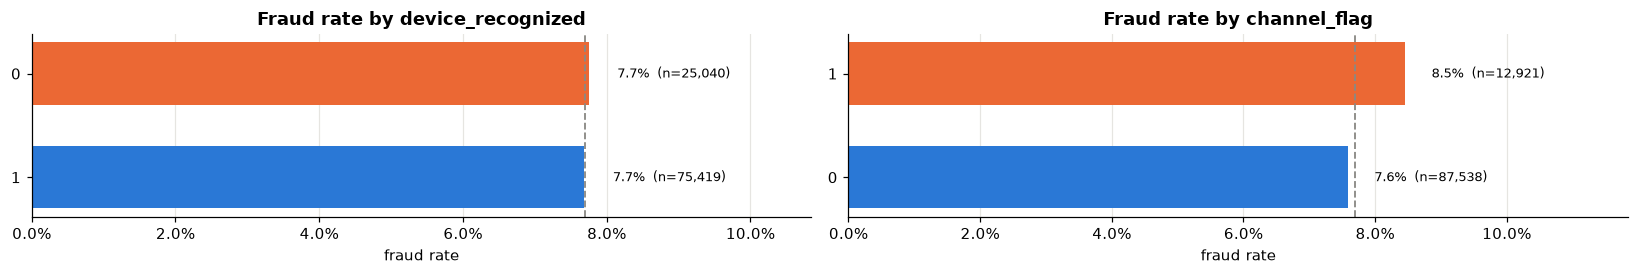

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 2.6))
fraud_rate_plot(df, "device_recognized", ax=axes[0])
fraud_rate_plot(df, "channel_flag", ax=axes[1])
plt.tight_layout(); plt.show()

* **Cash deposits (34.7%) and cash withdrawals (26.6%)** are 4–5× riskier than the base rate, followed by
  **cross-border** payments (18.1%). Card, ACH and cheque payments are all ≈4.3%, well below average.
  This matches classic money-laundering typologies (placement of cash, layering across borders).
* The **channel does not matter** (7.3–8.1%), nor does `device_recognized`. `channel_flag = 1` is slightly riskier (8.5% vs 7.6%).

### Q2. Are international transactions riskier? Which countries/currencies?

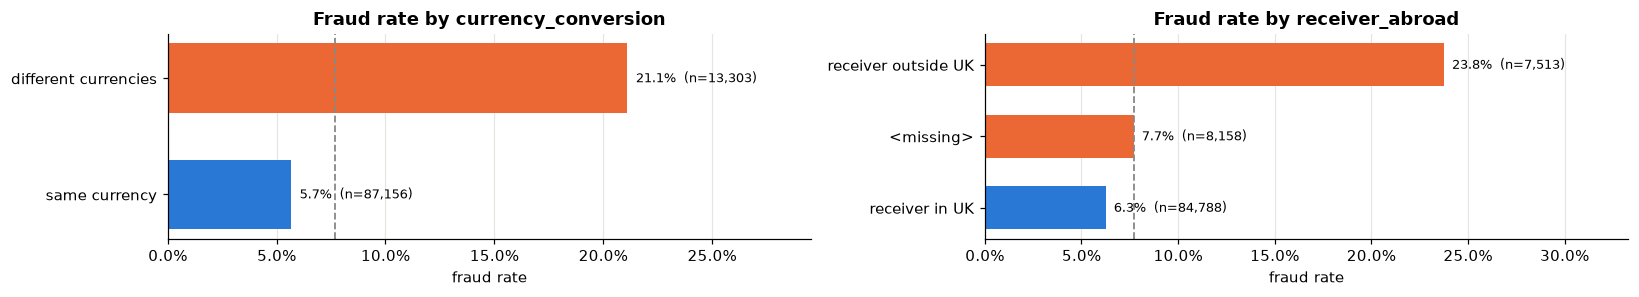

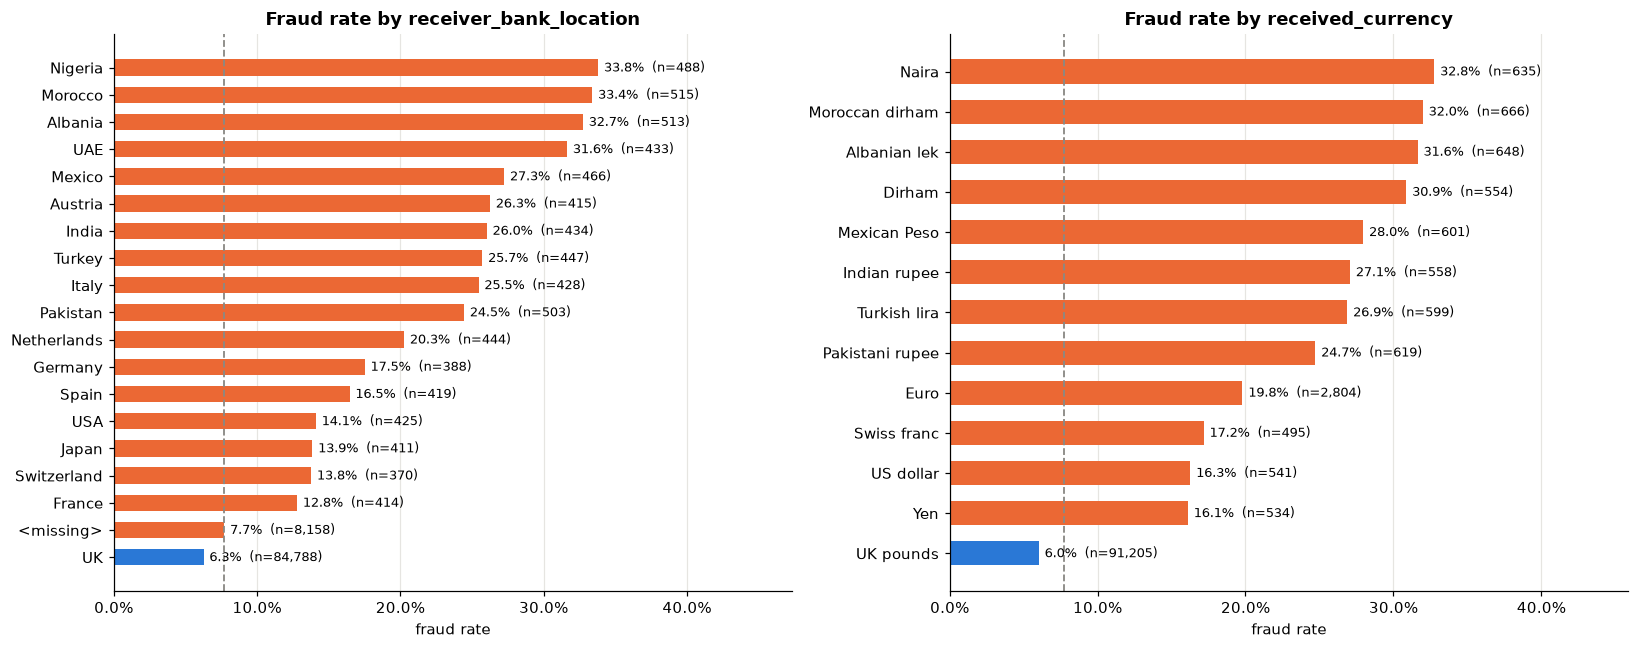

In [21]:
d2 = df.assign(
    currency_conversion=np.where(df.payment_currency != df.received_currency, "different currencies", "same currency"),
    receiver_abroad=np.where(df.receiver_bank_location.isna(), "<missing>",
                             np.where(df.receiver_bank_location != "UK", "receiver outside UK", "receiver in UK")))
fig, axes = plt.subplots(1, 2, figsize=(15, 2.8))
fraud_rate_plot(d2, "currency_conversion", ax=axes[0])
fraud_rate_plot(d2, "receiver_abroad", ax=axes[1])
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fraud_rate_plot(df, "receiver_bank_location", ax=axes[0])
fraud_rate_plot(df, "received_currency", ax=axes[1])
plt.tight_layout(); plt.show()

* Transactions **involving a currency conversion are 3.7× riskier** (21.1% vs 5.7%), and payments to a
  **receiver outside the UK** have a fraud rate of ~24% vs 6.3% for UK receivers.
* The destination matters more than the origin: **Nigeria, Morocco, Albania and the UAE** as receiver locations
  (and their currencies) show fraud rates above 30%, i.e. >4× the base rate. Lower-risk foreign destinations
  (France, Switzerland, Japan, USA) are still ~2× the base rate.
* Location and currency carry largely the same information (Section 2.3) — models should not need both, or they will
  be highly collinear.

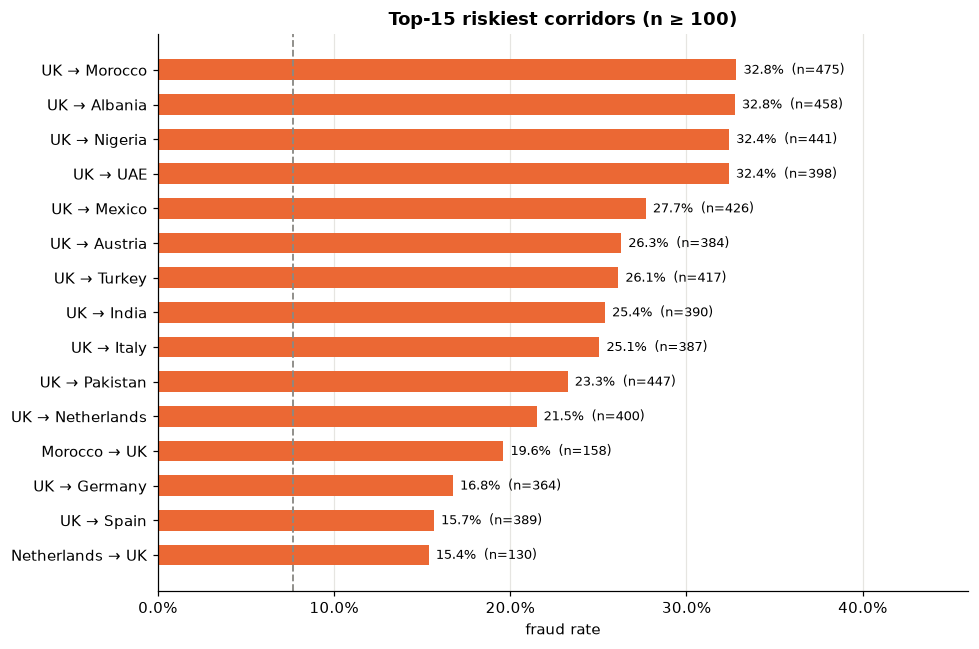

In [22]:
corr = (df.dropna(subset=["sender_bank_location", "receiver_bank_location"])
          .assign(corridor=lambda d: d.sender_bank_location + " → " + d.receiver_bank_location))
fig, ax = plt.subplots(figsize=(9, 6))
g = fraud_rate_plot(corr, "corridor", ax=ax, top=15, min_n=100, title="Top-15 riskiest corridors (n ≥ 100)")
plt.tight_layout(); plt.show()

The riskiest **corridors** all go **from the UK to a high-risk destination** (UK → Nigeria/Morocco/Albania/UAE…),
reinforcing that outbound transfers from UK accounts are the main laundering route in this data.

### Q3. Do fraudulent transactions involve different amounts?

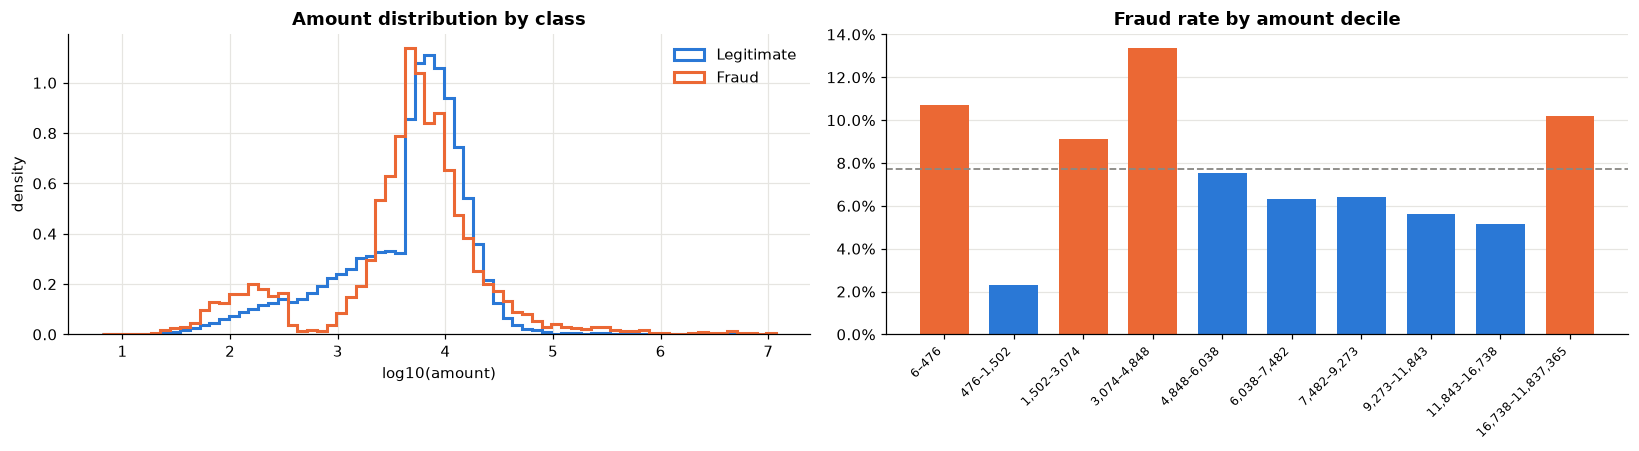

Amount > 99.0% quantile (53,271): fraud rate 32.5%
Amount > 99.9% quantile (573,318): fraud rate 67.3%
isFraud          median_legit  median_fraud
payment_type                               
ACH                 6,290.900     7,666.027
Cash Deposit        1,724.600     3,018.550
Cash Withdrawal       136.970       138.630
Cheque              6,410.475     7,507.905
Credit card         6,360.300     7,903.470
Cross-border        7,428.390     5,831.190
Debit card          6,351.680     7,829.870


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
bins = np.linspace(np.log10(df.amount.min()), np.log10(df.amount.max()), 70)
for lab, col, name in [(0, LEGIT, "Legitimate"), (1, FRAUD, "Fraud")]:
    axes[0].hist(np.log10(df.loc[df[TARGET] == lab, "amount"].dropna()), bins=bins, density=True,
                 histtype="step", lw=2, color=col, label=name)
axes[0].set_xlabel("log10(amount)"); axes[0].set_ylabel("density"); axes[0].legend()
axes[0].set_title("Amount distribution by class")

dec = df.assign(amount_decile=pd.qcut(df.amount, 10))
g = dec.groupby("amount_decile", observed=True)[TARGET].mean()
labels = [f"{iv.left:,.0f}–{iv.right:,.0f}" for iv in g.index]
axes[1].bar(range(10), g.values, color=[FRAUD if v > BASE_RATE else LEGIT for v in g.values], width=0.7)
axes[1].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
axes[1].set_xticks(range(10)); axes[1].set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Fraud rate by amount decile")
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

for q in [.99, .999]:
    thr = df.amount.quantile(q)
    print(f"Amount > {q:.1%} quantile ({thr:,.0f}): fraud rate {df.loc[df.amount > thr, TARGET].mean():.1%}")
print(df.groupby(["payment_type", TARGET]).amount.median().unstack().rename(columns={0: "median_legit", 1: "median_fraud"}))

* The relationship is **non-monotonic**: fraud concentrates in very small amounts (<476: 10.7%), in the **3,000–4,850
  band (13.3%)** and in the extreme tail — above the 99th percentile the fraud rate is **33%**, above the 99.9th it is **67%**.
  The 476–1,500 band is almost fraud-free (2.3%).
* Within most payment types, fraudulent transfers have a ~20% higher median amount; cross-border fraud is the exception
  (lower median), consistent with "smurfing" (splitting money into smaller transfers).
* Implication: the extreme amounts are **not errors to be removed** — they are the most informative observations.
  We will log-transform rather than clip/drop outliers. Tree-based models can exploit the non-monotonic pattern
  directly.

### Q4. Are there temporal patterns?

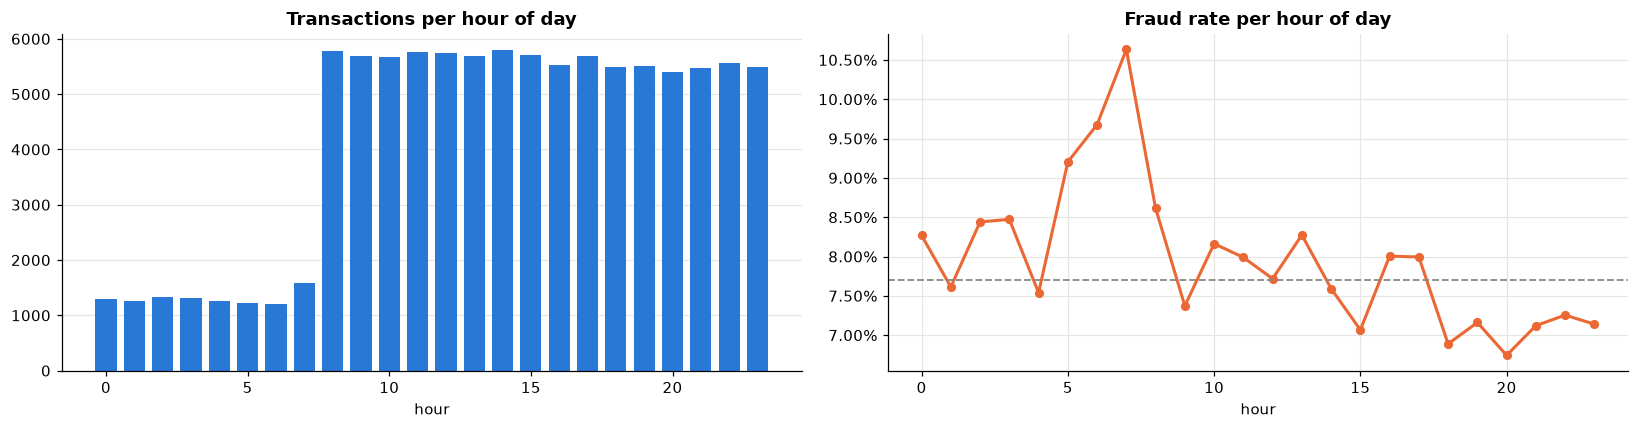

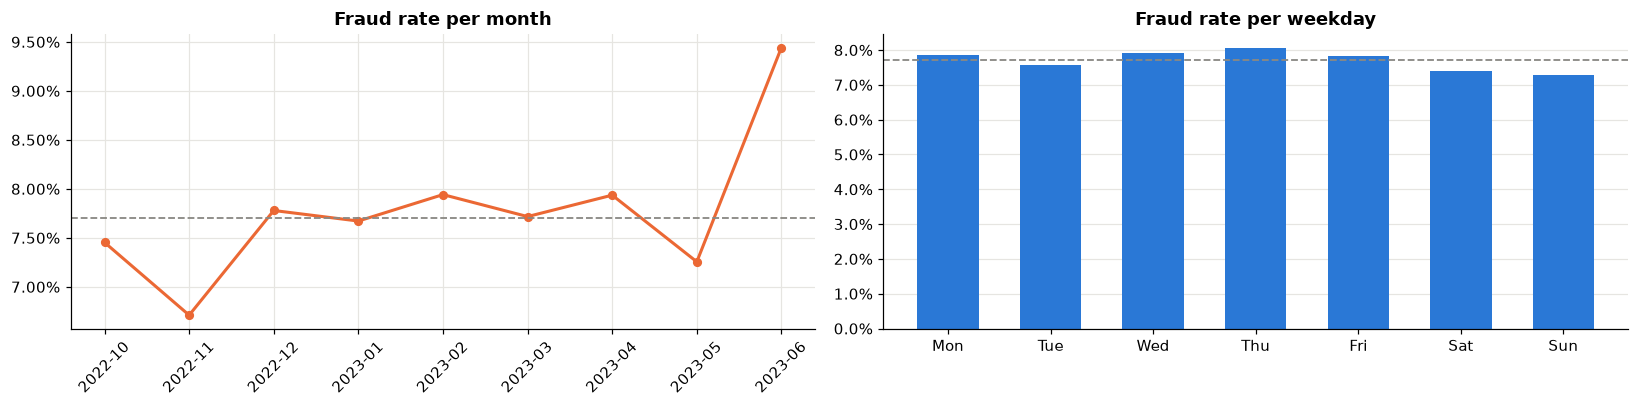

Rows per month: {'2022-10': 9311, '2022-11': 11831, '2022-12': 11659, '2023-01': 12253, '2023-02': 11912, '2023-03': 12012, '2023-04': 12122, '2023-05': 11935, '2023-06': 7424}


In [24]:
dt = pd.to_datetime(df.date + " " + df.time)
tmp = df.assign(hour=dt.dt.hour, weekday=dt.dt.day_name().str[:3], month=dt.dt.to_period("M").astype(str))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
h = tmp.groupby("hour")[TARGET].agg(["mean", "size"])
axes[0].bar(h.index, h["size"], color=LEGIT, width=0.75)
axes[0].set_title("Transactions per hour of day"); axes[0].set_xlabel("hour"); axes[0].grid(axis="x", visible=False)
axes[1].plot(h.index, h["mean"], color=FRAUD, lw=2, marker="o", ms=5)
axes[1].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Fraud rate per hour of day"); axes[1].set_xlabel("hour")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
m = tmp.groupby("month")[TARGET].agg(["mean", "size"])
axes[0].plot(m.index, m["mean"], color=FRAUD, lw=2, marker="o", ms=5)
axes[0].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title("Fraud rate per month"); axes[0].tick_params(axis="x", rotation=45)
w = tmp.groupby("weekday")[TARGET].mean().reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axes[1].bar(w.index, w.values, color=LEGIT, width=0.6); axes[1].axhline(BASE_RATE, color=GRAY, ls="--", lw=1.2)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].set_title("Fraud rate per weekday")
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print("Rows per month:", m["size"].to_dict())

* Activity is ~4.5× lower between 00:00 and 07:59 than during the day. Fraud rate is **slightly higher in the early
  morning (05:00–07:59, 9–11%)** and lowest in the evening (~7%). An `hour` / `is_night` feature is mildly useful.
* Weekday has a negligible effect (7.3–8.1%, slightly lower at weekends).
* The data covers **Oct-2022 to Jun-2023**; October and June are partial months. Fraud rate is stable over time
  (6.7–7.9%) except June 2023 (9.4%) — worth keeping in mind if the test set is a later period (possible drift).
  The date itself should not be used as a raw feature.

### Q5. Do the behavioural and device scores separate fraud from legitimate transactions?

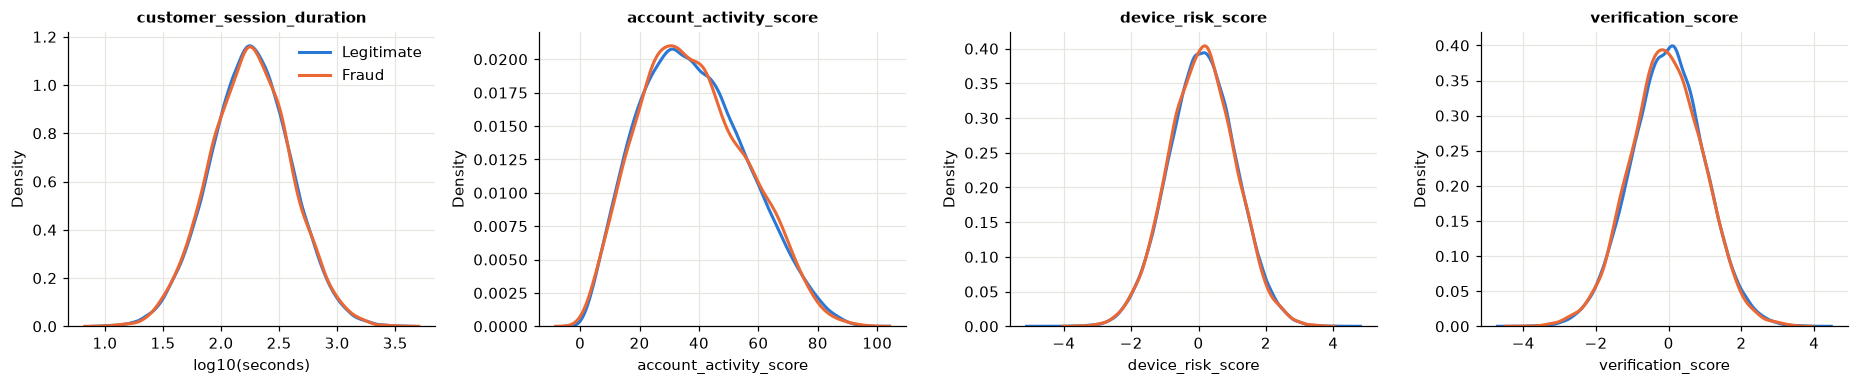

,mean_legit,mean_fraud,KS_stat,p_value
feature,,,,
customer_session_duration,2.255,2.253,0.008,0.683
account_activity_score,38.339,38.286,0.010,0.515
device_risk_score,0.115,0.099,0.013,0.226
verification_score,-0.018,-0.052,0.021,0.004
amount (reference),NaN,NaN,0.072,0.000


In [25]:
score_cols = ["customer_session_duration", "account_activity_score", "device_risk_score", "verification_score"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
rows = []
for ax, c in zip(axes, score_cols):
    a, b = df.loc[df[TARGET] == 0, c].dropna(), df.loc[df[TARGET] == 1, c].dropna()
    if c == "customer_session_duration":
        a, b = np.log10(a), np.log10(b); ax.set_xlabel("log10(seconds)")
    sns.kdeplot(a, ax=ax, color=LEGIT, lw=2, label="Legitimate")
    sns.kdeplot(b, ax=ax, color=FRAUD, lw=2, label="Fraud")
    ax.set_title(c, fontsize=10)
    ks = ks_2samp(a, b)
    rows.append({"feature": c, "mean_legit": a.mean(), "mean_fraud": b.mean(), "KS_stat": ks.statistic, "p_value": ks.pvalue})
axes[0].legend()
plt.tight_layout(); plt.show()
ks_amt = ks_2samp(df.loc[df[TARGET] == 0, "amount"].dropna(), df.loc[df[TARGET] == 1, "amount"].dropna())
rows.append({"feature": "amount (reference)", "KS_stat": ks_amt.statistic, "p_value": ks_amt.pvalue})
pd.DataFrame(rows).set_index("feature")

A surprising and important finding: **the four behavioural/device scores have practically identical distributions
for both classes** (Kolmogorov–Smirnov statistic ≤ 0.02, vs 0.07 for `amount`; only `verification_score` reaches
p < 0.01 with a negligible effect size). Together with `device_recognized` and `transaction_channel` (Q1), these
variables look like **noise with respect to the target** — they are individually near-useless for detecting fraud.
They are kept for now (they could still matter in interactions) but are prime candidates for feature selection.

### Q6. Do account-level (network) patterns reveal fraud?

Each row is a single transaction, but accounts appear many times. Aggregating by `sender_id` and `receiver_id` gives
each transaction a view of its accounts' behaviour: how many transactions they make, with how many distinct counterparts.

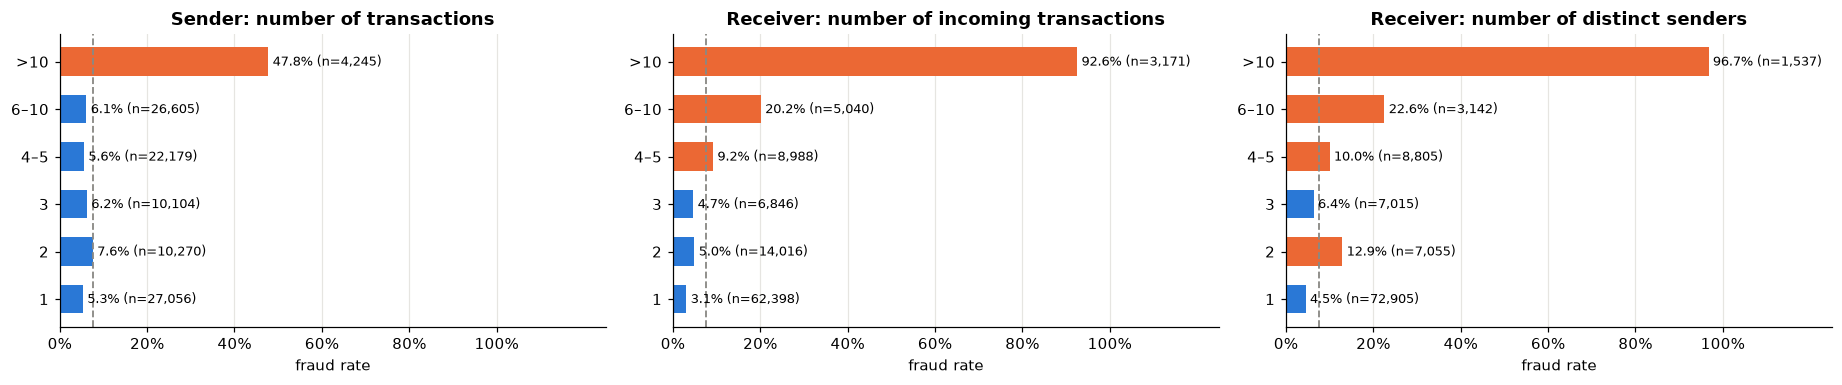

In [26]:
acc = df.copy()
acc["sender_tx_count"] = acc.groupby("sender_id")["transaction_id"].transform("size")
acc["sender_unique_receivers"] = acc.groupby("sender_id")["receiver_id"].transform("nunique")
acc["receiver_tx_count"] = acc.groupby("receiver_id")["transaction_id"].transform("size")
acc["receiver_unique_senders"] = acc.groupby("receiver_id")["sender_id"].transform("nunique")
acc["pair_tx_count"] = acc.groupby(["sender_id", "receiver_id"])["transaction_id"].transform("size")

edges = [0, 1, 2, 3, 5, 10, 1000]
labels = ["1", "2", "3", "4–5", "6–10", ">10"]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, c, t in [(axes[0], "sender_tx_count", "Sender: number of transactions"),
                 (axes[1], "receiver_tx_count", "Receiver: number of incoming transactions"),
                 (axes[2], "receiver_unique_senders", "Receiver: number of distinct senders")]:
    # bars kept in bucket order (not sorted by rate) to show the trend
    g = acc.groupby(pd.cut(acc[c], edges, labels=labels), observed=True)[TARGET].agg(["mean", "size"])
    ax.barh(g.index.astype(str), g["mean"], color=[FRAUD if m > BASE_RATE else LEGIT for m in g["mean"]], height=0.6)
    for i, (mm, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(mm + 0.01, i, f"{mm:.1%} (n={n:,})", va="center", fontsize=8.5)
    ax.axvline(BASE_RATE, color=GRAY, ls="--", lw=1.2); ax.set_xlim(0, 1.25); ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title(t); ax.grid(axis="y", visible=False)
    ax.set_xlabel("fraud rate")
plt.tight_layout(); plt.show()

In [27]:
g = acc.groupby("pair_tx_count")[TARGET].agg(["mean", "size"]).rename(columns={"mean": "fraud_rate", "size": "n_tx"})
print("Fraud rate by number of transactions between the same sender→receiver pair:")
g.head(12)

Fraud rate by number of transactions between the same sender→receiver pair:


,fraud_rate,n_tx
pair_tx_count,,
1,0.069,85880
2,0.000,11494
3,0.000,1140
4,0.229,140
5,0.714,70
6,1.000,66
7,1.000,84
8,1.000,64
9,1.000,36


In [28]:
s = acc.groupby("sender_id")[TARGET].agg(["size", "mean"])
multi = s[s["size"] > 1]
print(f"Senders with >1 transaction: {len(multi):,}")
print(f"  ... all transactions fraudulent: {(multi['mean'] == 1).mean():.1%}")
print(f"  ... mixed (some fraud, some legit): {((multi['mean'] > 0) & (multi['mean'] < 1)).mean():.1%}")
print(f"  ... never fraudulent: {(multi['mean'] == 0).mean():.1%}")

Senders with >1 transaction: 17,539
  ... all transactions fraudulent: 2.1%
  ... mixed (some fraud, some legit): 12.1%
  ... never fraudulent: 85.7%


This is the **strongest signal in the dataset**:

* Receivers with **more than 10 incoming transactions are fraudulent 93% of the time**, and receivers paid by more
  than 10 distinct senders 97% of the time — a typical **fan-in / "money mule" collection account** pattern.
* Senders with **more than 10 outgoing transactions** have a 48% fraud rate (fan-out).
* Repeated payments between the same pair behave very differently: 2–3 transactions → 0% fraud (looks like
  recurring legitimate payments), 4 → 23%, 5 → 71% and **6 or more → 100% fraud** (structuring).

**Caveat for modelling:** these aggregates are computed over the whole training set, so they "see the future" of each
account. For a predictive model they must be computed in a leakage-safe way — e.g. only from past transactions
(rolling/expanding windows by date-time), or on train+test features only (never using the label) — and with
cross-validation that groups by account.

### Q7. Overall: which variables carry the most information about fraud?

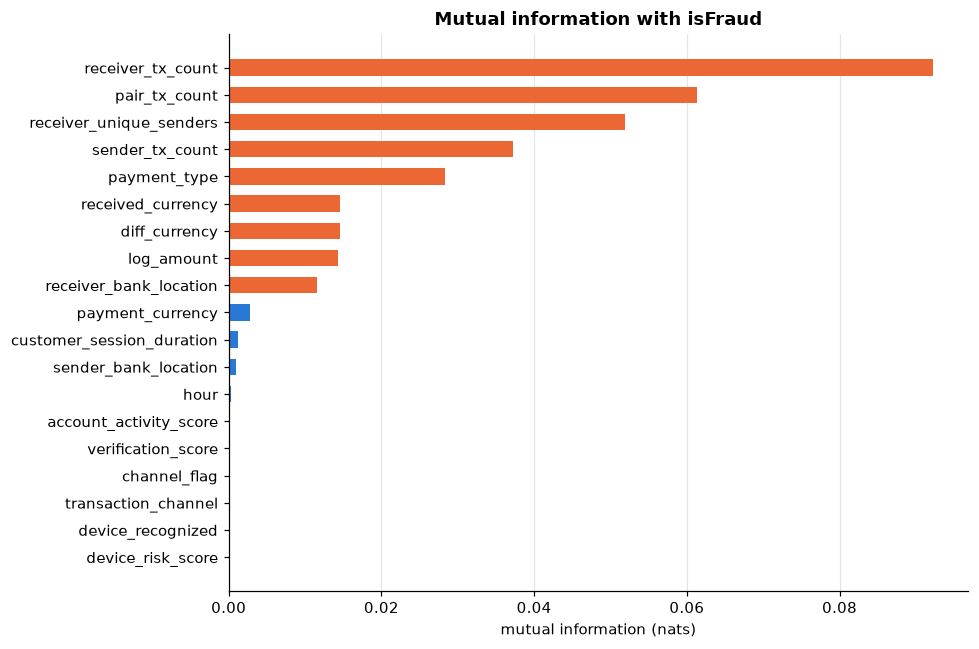

In [29]:
mi_df = acc.copy()
mi_df["log_amount"] = np.log1p(mi_df["amount"])
mi_df["hour"] = dt.dt.hour
mi_df["diff_currency"] = (mi_df.payment_currency != mi_df.received_currency).astype(int)
mi_features = ["log_amount", "customer_session_duration", "account_activity_score", "device_risk_score",
               "verification_score", "device_recognized", "channel_flag", "hour", "diff_currency",
               "payment_type", "transaction_channel", "payment_currency", "received_currency",
               "sender_bank_location", "receiver_bank_location",
               "sender_tx_count", "receiver_tx_count", "receiver_unique_senders", "pair_tx_count"]
X = mi_df[mi_features].copy()
discrete = []
for c in X.columns:
    if X[c].dtype == object or str(X[c].dtype) in ("str", "string"):
        X[c] = X[c].fillna("<missing>").astype("category").cat.codes
        discrete.append(True)
    else:
        X[c] = X[c].fillna(X[c].median())
        discrete.append(c in ["device_recognized", "channel_flag", "hour", "diff_currency"])
mi = pd.Series(mutual_info_classif(X, mi_df[TARGET], discrete_features=discrete, random_state=RANDOM_STATE),
               index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mi.index, mi.values, color=[FRAUD if v > 0.01 else LEGIT for v in mi.values], height=0.6)
ax.set_title("Mutual information with isFraud"); ax.set_xlabel("mutual information (nats)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

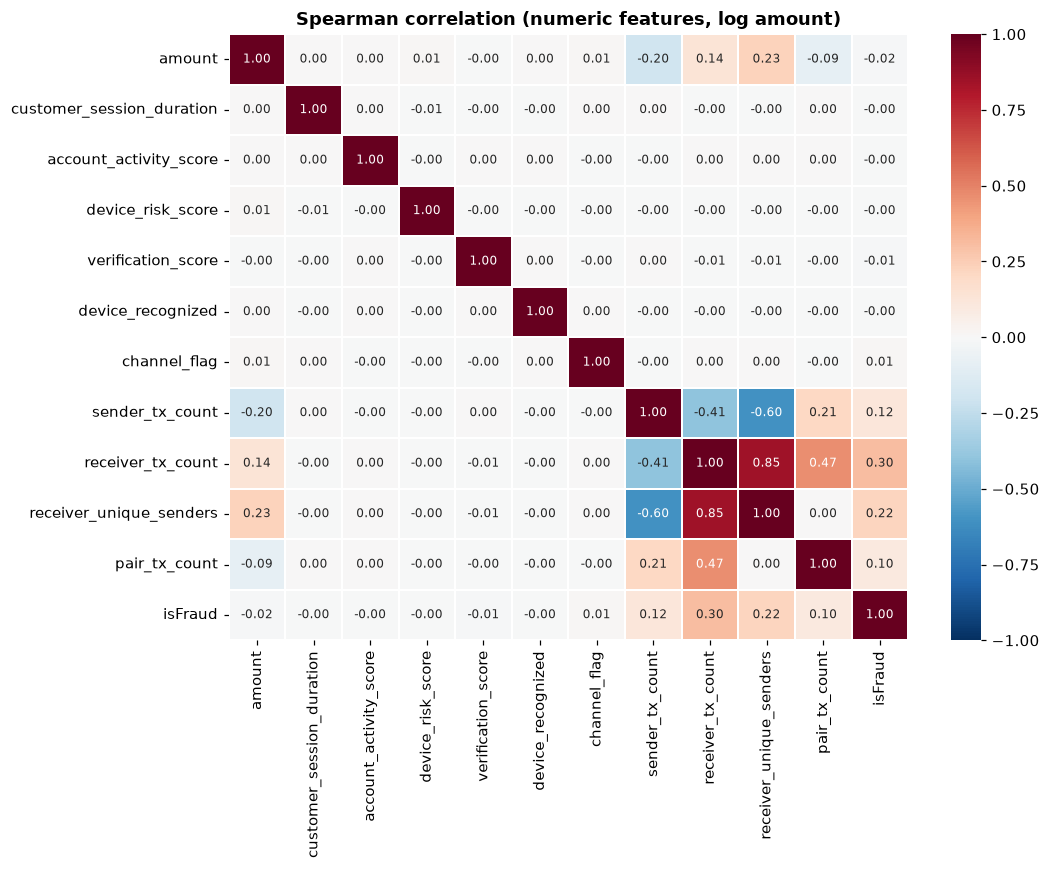

In [30]:
num_corr = acc[NUM + BIN + ["sender_tx_count", "receiver_tx_count", "receiver_unique_senders", "pair_tx_count", TARGET]].copy()
num_corr["amount"] = np.log1p(num_corr["amount"])
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num_corr.corr(method="spearman"), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.3, ax=ax)
ax.set_title("Spearman correlation (numeric features, log amount)")
plt.tight_layout(); plt.show()

The mutual-information ranking summarises the analysis: **account-level counts** dominate, followed by
**payment type, destination and currency** variables and `amount`. The behavioural/device scores, channel and
`device_recognized` carry essentially no information.

The correlation matrix shows that the original numeric features are **mutually uncorrelated** (no redundancy to remove),
while the engineered account features are correlated with each other (e.g. receiver transaction count vs distinct
senders, ρ = 0.85) — only one of each related pair may be needed.

## 6. Descriptive modelling — clustering sender accounts

Clustering raw transactions mostly groups by the noisy score variables, so we cluster at the **sender-account level**,
describing *how each account behaves*. The label is **not** used to build the clusters; it is used afterwards to check
whether the discovered profiles differ in fraud risk.

Features per sender (log-transformed where skewed, then standardised):
number of transactions, distinct receivers, mean and max amount, and the share of transactions that are cross-border,
cash, involve a currency conversion, go to a non-UK receiver, or happen at night (00:00–07:59).

In [31]:
cl = df.assign(
    hour=dt.dt.hour,
    is_cash=df.payment_type.isin(["Cash Deposit", "Cash Withdrawal"]).astype(int),
    is_cross_border=(df.payment_type == "Cross-border").astype(int),
    diff_currency=(df.payment_currency != df.received_currency).astype(int),
    receiver_abroad=(df.receiver_bank_location.notna() & (df.receiver_bank_location != "UK")).astype(int),
    log_amount=np.log1p(df.amount),
)
cl["is_night"] = (cl.hour < 8).astype(int)

senders = cl.groupby("sender_id").agg(
    n_tx=("transaction_id", "size"),
    n_receivers=("receiver_id", "nunique"),
    mean_log_amount=("log_amount", "mean"),
    max_log_amount=("log_amount", "max"),
    share_cash=("is_cash", "mean"),
    share_cross_border=("is_cross_border", "mean"),
    share_diff_currency=("diff_currency", "mean"),
    share_receiver_abroad=("receiver_abroad", "mean"),
    share_night=("is_night", "mean"),
    fraud_rate=(TARGET, "mean"),           # NOT used for clustering, only for profiling
)
senders["any_fraud"] = (senders.fraud_rate > 0).astype(int)
senders[["mean_log_amount", "max_log_amount"]] = senders[["mean_log_amount", "max_log_amount"]].fillna(
    senders[["mean_log_amount", "max_log_amount"]].median())

CL_FEATURES = ["n_tx", "n_receivers", "mean_log_amount", "max_log_amount", "share_cash", "share_cross_border",
               "share_diff_currency", "share_receiver_abroad", "share_night"]
Xc = senders[CL_FEATURES].copy()
Xc[["n_tx", "n_receivers"]] = np.log1p(Xc[["n_tx", "n_receivers"]])
Xs = StandardScaler().fit_transform(Xc)
print(f"{len(senders):,} sender accounts x {len(CL_FEATURES)} features")

44,595 sender accounts x 9 features


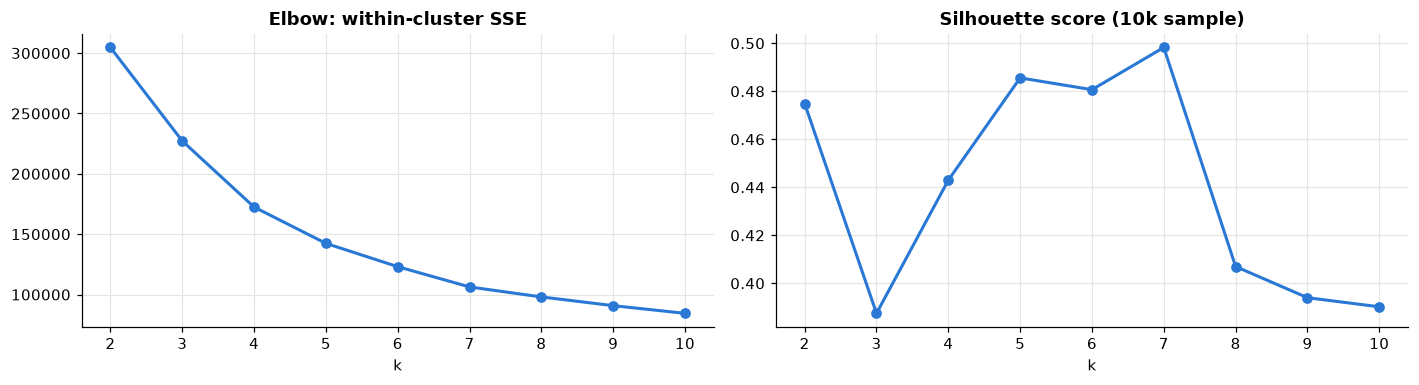

{2: 0.475, 3: 0.387, 4: 0.443, 5: 0.486, 6: 0.481, 7: 0.498, 8: 0.407, 9: 0.394, 10: 0.39}


In [32]:
ks = range(2, 11)
inertia, sil = [], []
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(Xs), size=10_000, replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xs[sample_idx], km.labels_[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(list(ks), inertia, marker="o", color=LEGIT, lw=2); axes[0].set_title("Elbow: within-cluster SSE")
axes[1].plot(list(ks), sil, marker="o", color=LEGIT, lw=2); axes[1].set_title("Silhouette score (10k sample)")
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plt.show()
print(pd.Series(sil, index=list(ks)).round(3).to_dict())

In [33]:
K = int(pd.Series(sil, index=list(ks)).idxmax())   # k with the best silhouette
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Xs)
senders["cluster"] = km.labels_
print("Chosen k =", K)

profile = senders.groupby("cluster").agg(
    n_senders=("n_tx", "size"),
    n_tx_mean=("n_tx", "mean"), n_receivers_mean=("n_receivers", "mean"),
    amount_median=("mean_log_amount", lambda x: np.expm1(x.median())),
    share_cash=("share_cash", "mean"), share_cross_border=("share_cross_border", "mean"),
    share_diff_currency=("share_diff_currency", "mean"), share_receiver_abroad=("share_receiver_abroad", "mean"),
    share_night=("share_night", "mean"),
    senders_with_fraud=("any_fraud", "mean"),
)
tx_fraud = cl.assign(cluster=cl.sender_id.map(senders.cluster)).groupby("cluster")[TARGET].agg(["mean", "size"])
profile["n_transactions"] = tx_fraud["size"]
profile["tx_fraud_rate"] = tx_fraud["mean"]
profile.sort_values("tx_fraud_rate", ascending=False)

Chosen k = 7


,n_senders,n_tx_mean,n_receivers_mean,amount_median,share_cash,share_cross_border,share_diff_currency,share_receiver_abroad,share_night,senders_with_fraud,n_transactions,tx_fraud_rate
cluster,,,,,,,,,,,,
4,2407,1.536,1.039,"1,636.500",0.992,0.001,0.025,0.008,0.112,0.108,3696,0.358
2,2635,1.502,1.444,"7,485.460",0.005,0.683,0.903,0.080,0.073,0.206,3958,0.165
5,2302,1.162,1.109,"8,126.528",0.000,0.934,0.985,0.987,0.093,0.126,2675,0.151
0,10601,5.296,4.882,"4,014.098",0.039,0.084,0.110,0.067,0.102,0.144,56144,0.070
3,2829,1.265,1.157,"7,971.950",0.007,0.002,0.029,0.003,0.891,0.075,3580,0.066
6,19885,1.141,1.067,"8,638.470",0.001,0.000,0.003,0.000,0.001,0.044,22691,0.040
1,3936,1.960,1.799,"1,126.631",0.057,0.018,0.035,0.015,0.067,0.063,7715,0.033


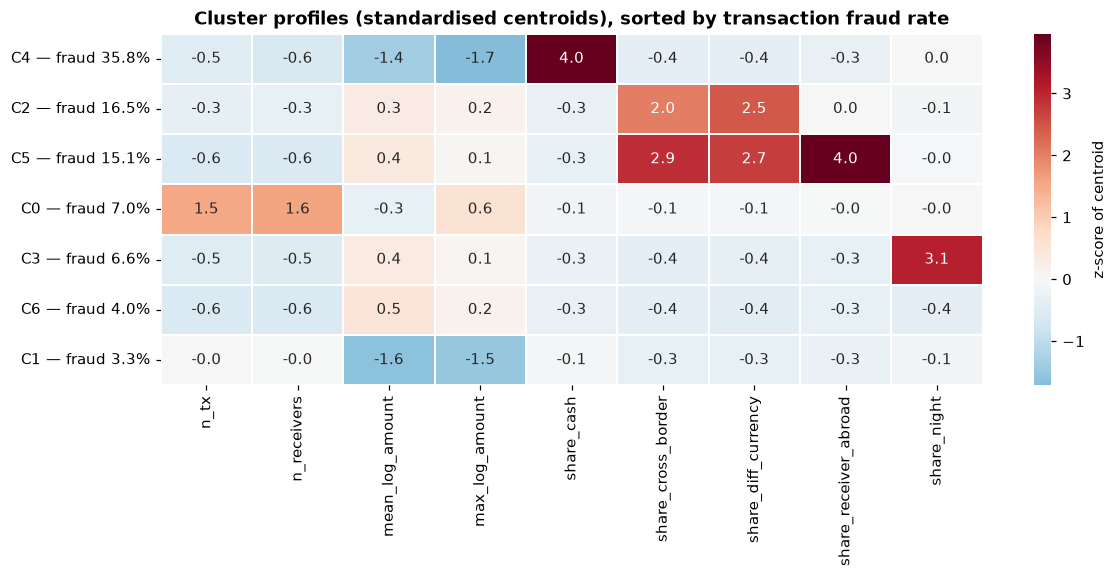

In [34]:
# Standardised cluster centroids: how each cluster deviates from the average sender
cent = pd.DataFrame(km.cluster_centers_, columns=CL_FEATURES)
order = profile.sort_values("tx_fraud_rate", ascending=False).index
cent = cent.loc[order]
cent.index = [f"C{c} — fraud {profile.loc[c, 'tx_fraud_rate']:.1%}" for c in order]
fig, ax = plt.subplots(figsize=(11, 0.55 * K + 1.5))
sns.heatmap(cent, cmap="RdBu_r", center=0, annot=True, fmt=".1f", linewidths=0.3, ax=ax,
            cbar_kws={"label": "z-score of centroid"})
ax.set_title("Cluster profiles (standardised centroids), sorted by transaction fraud rate")
plt.tight_layout(); plt.show()

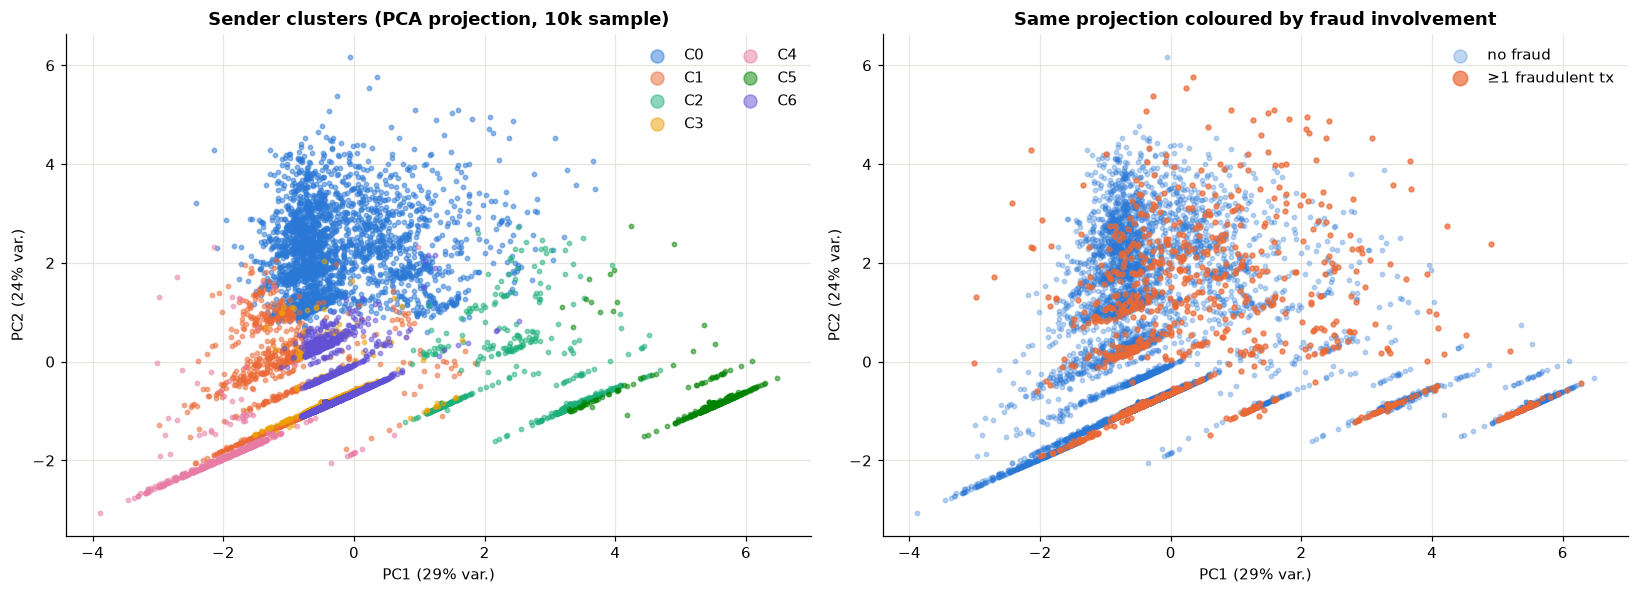

In [35]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xs)
P = pca.transform(Xs[sample_idx])
lab = senders.cluster.values[sample_idx]
fr = senders.any_fraud.values[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
for c in range(K):
    m = lab == c
    axes[0].scatter(P[m, 0], P[m, 1], s=8, alpha=0.5, color=palette[c % len(palette)], label=f"C{c}")
axes[0].legend(markerscale=3, ncol=2); axes[0].set_title("Sender clusters (PCA projection, 10k sample)")
axes[1].scatter(P[fr == 0, 0], P[fr == 0, 1], s=8, alpha=0.3, color=LEGIT, label="no fraud")
axes[1].scatter(P[fr == 1, 0], P[fr == 1, 1], s=10, alpha=0.7, color=FRAUD, label="≥1 fraudulent tx")
axes[1].legend(markerscale=3); axes[1].set_title("Same projection coloured by fraud involvement")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var.)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var.)")
plt.tight_layout(); plt.show()

**Interpretation.** Even though the label was never used, K-Means separates sender accounts into behavioural profiles
with very different fraud risk (silhouette is highest at k = 7; see the profile table and heatmap above):

| Profile | Defining traits | Senders | Tx fraud rate |
|---|---|---|---|
| **Cash** | ~99% cash deposits/withdrawals, small amounts | ~2.4k | **35.8%** (4.6× base) |
| **Inbound international** | cross-border with currency conversion, receiver mostly in the UK | ~2.6k | **16.5%** |
| **Outbound international** | cross-border to a receiver abroad | ~2.3k | **15.1%** |
| **Multi-transaction domestic** | ~5 transactions to ~5 receivers on average | ~10.6k | 7.0% (≈ base) |
| **Night-time** | ~90% of activity between 00:00 and 08:00 | ~2.8k | 6.6% |
| **One-off domestic** | single daytime UK→UK card/ACH/cheque payment | ~19.9k | 4.0% |
| **Small-amount domestic** | domestic, low amounts | ~3.9k | 3.3% |

* The clusters reproduce the transaction-level findings without using the label: **cash** and **international**
  behaviour are the high-risk profiles, while plain domestic payments (most accounts) are low-risk.
* The night-time profile is only marginally risky, consistent with the small hourly effect in Q4.
* The multi-transaction cluster sits at the base rate: the extreme fan-out senders (>10 transactions, 48% fraud) are
  too few to form their own centroid and get absorbed into it. Clustering is therefore a complement to, not a
  replacement for, explicit account-level features.

The cluster membership (or the distance to each centroid) can be used as a compact engineered feature in Task 2,
and the profiles give an interpretable segmentation for analysts: the low-risk domestic segment could receive lighter
monitoring, while the cash/international/high-activity segments deserve closer scrutiny.

## 7. Data cleaning & pre-processing

Based on the audit and the exploratory analysis, the following steps are applied:

| # | Issue found | Decision |
|---|---|---|
| 1 | `transaction_id` is a row ID | Drop |
| 2 | `date`/`time` stored as text | Parse to a timestamp; derive `hour`, `day_of_week`, `month`, `is_night`; drop raw strings |
| 3 | Missing locations (5–8%), mostly GBP rows | Impute `UK` when the currency is GBP (>99.9% rule), else `Unknown`; keep a missing flag |
| 4 | Missing `payment_type` (6%) | `Cross-border` when sender/receiver locations differ (97% rule), else `Unknown` |
| 5 | Missing `transaction_channel` (4%) | New category `Unknown` (missingness not informative) |
| 6 | Missing `amount` (3%), slightly informative | Median imputation **per payment type** (amounts differ by type by ~50×) + missing flag |
| 7 | Missing `account_activity_score`, `device_risk_score` (5–10%) | Median imputation (variables are near-uninformative) |
| 8 | `amount` very skewed, extreme values highly fraudulent | Keep outliers; add `log_amount` |
| 9 | `customer_session_duration` skewed | Add `log_session_duration` |
| 10 | International signal spread over 4 columns | Add `diff_currency`, `diff_location`, `sender_abroad`, `receiver_abroad`, `is_cash` |
| 11 | Strong account-level signal | Add sender/receiver/pair transaction counts *(must be recomputed leakage-safely for modelling)* |

Left for the modelling stage (must be fitted on the training fold only): one-hot encoding of the categorical variables,
standardisation for distance-based/linear models, and class-imbalance handling (class weights / resampling).

In [36]:
def preprocess(raw: pd.DataFrame) -> pd.DataFrame:
    d = raw.copy()

    # 1-2. identifiers and timestamps
    d = d.drop(columns=["transaction_id"])
    ts = pd.to_datetime(d["date"] + " " + d["time"], format="%Y-%m-%d %H:%M:%S")
    d["hour"] = ts.dt.hour
    d["day_of_week"] = ts.dt.dayofweek
    d["month"] = ts.dt.month
    d["is_night"] = (d["hour"] < 8).astype(int)
    d["timestamp"] = ts
    d = d.drop(columns=["date", "time"])

    # 3. locations: GBP -> UK, otherwise Unknown
    for loc, cur in [("sender_bank_location", "payment_currency"), ("receiver_bank_location", "received_currency")]:
        miss = d[loc].isna()
        d[f"{loc}_missing"] = miss.astype(int)
        d.loc[miss & (d[cur] == "UK pounds"), loc] = "UK"
        d[loc] = d[loc].fillna("Unknown")

    # 4. payment type: Cross-border when the two (known) locations differ
    known_diff = ((d.sender_bank_location != d.receiver_bank_location)
                  & (d.sender_bank_location != "Unknown") & (d.receiver_bank_location != "Unknown"))
    miss = d["payment_type"].isna()
    d.loc[miss & known_diff, "payment_type"] = "Cross-border"
    d["payment_type"] = d["payment_type"].fillna("Unknown")

    # 5. channel
    d["transaction_channel"] = d["transaction_channel"].fillna("Unknown")

    # 6. amount: median per payment type + flag
    d["amount_missing"] = d["amount"].isna().astype(int)
    d["amount"] = d["amount"].fillna(d.groupby("payment_type")["amount"].transform("median"))
    d["amount"] = d["amount"].fillna(d["amount"].median())

    # 7. scores
    for c in ["account_activity_score", "device_risk_score"]:
        d[c] = d[c].fillna(d[c].median())

    # 8-9. transforms
    d["log_amount"] = np.log1p(d["amount"])
    d["log_session_duration"] = np.log1p(d["customer_session_duration"])

    # 10. international / cash indicators
    d["diff_currency"] = (d.payment_currency != d.received_currency).astype(int)
    d["diff_location"] = known_diff.astype(int)
    d["sender_abroad"] = (~d.sender_bank_location.isin(["UK", "Unknown"])).astype(int)
    d["receiver_abroad"] = (~d.receiver_bank_location.isin(["UK", "Unknown"])).astype(int)
    d["is_cash"] = d.payment_type.isin(["Cash Deposit", "Cash Withdrawal"]).astype(int)

    # 11. account-level aggregates (label-free; recompute leakage-safely when modelling)
    d["sender_tx_count"] = d.groupby("sender_id")["amount"].transform("size")
    d["sender_unique_receivers"] = d.groupby("sender_id")["receiver_id"].transform("nunique")
    d["receiver_tx_count"] = d.groupby("receiver_id")["amount"].transform("size")
    d["receiver_unique_senders"] = d.groupby("receiver_id")["sender_id"].transform("nunique")
    d["pair_tx_count"] = d.groupby(["sender_id", "receiver_id"])["amount"].transform("size")
    return d

clean = preprocess(df)
print("Shape after pre-processing:", clean.shape)
print("Remaining missing values:", int(clean.isna().sum().sum()))
clean.head()

Shape after pre-processing: (100459, 36)
Remaining missing values: 0


,sender_id,receiver_id,amount,payment_currency,received_currency,sender_bank_location,receiver_bank_location,payment_type,customer_session_duration,account_activity_score,transaction_channel,device_recognized,device_risk_score,verification_score,channel_flag,isFraud,hour,day_of_week,month,is_night,timestamp,sender_bank_location_missing,receiver_bank_location_missing,amount_missing,log_amount,log_session_duration,diff_currency,diff_location,sender_abroad,receiver_abroad,is_cash,sender_tx_count,sender_unique_receivers,receiver_tx_count,receiver_unique_senders,pair_tx_count
0,AA49C7A57304F7CF25AFC3B34,A1B80787BB81A17BCF1093FEA,971.580,UK pounds,UK pounds,UK,UK,ACH,200,40.000,POS,0,-1.161,-1.272,0,0,9,2,4,0,2023-04-19 09:44:51,0,0,0,6.880,5.303,0,0,0,0,0,4,4,1,1,1
1,AF929BA0C0E9FDF79640B04DB,AB88EA36C2764248B1083497E,56.000,UK pounds,UK pounds,UK,UK,ACH,308,62.300,Other,0,0.534,0.024,0,0,18,4,11,0,2022-11-11 18:47:13,0,0,0,4.043,5.733,0,0,0,0,0,8,8,1,1,1
2,A1F5681C7C087BB287F571BF9,A77801AFFD4C07AA5C581067B,"7,079.230",UK pounds,UK pounds,UK,UK,Credit card,211,31.000,Other,1,0.393,1.409,0,0,3,3,2,1,2023-02-09 03:00:23,0,0,0,8.865,5.357,0,0,0,0,0,3,2,2,1,2
3,AB298058402D02A7913DB3606,AB4371723703DB467AD2A1946,"25,042.780",UK pounds,UK pounds,UK,UK,ACH,99,21.200,Other,1,0.934,-2.564,0,0,13,4,4,0,2023-04-21 13:10:01,0,1,0,10.128,4.605,0,0,0,0,0,1,1,5,5,1
4,AECDF0440A068E3C82552C44C,A1CDD50184E01956054934B30,"4,580.900",Albanian lek,UK pounds,Albania,UK,Cross-border,85,29.800,Mobile App,1,0.219,2.443,0,1,16,6,3,0,2023-03-05 16:16:50,0,0,0,8.430,4.454,1,1,1,0,0,3,3,9,9,1


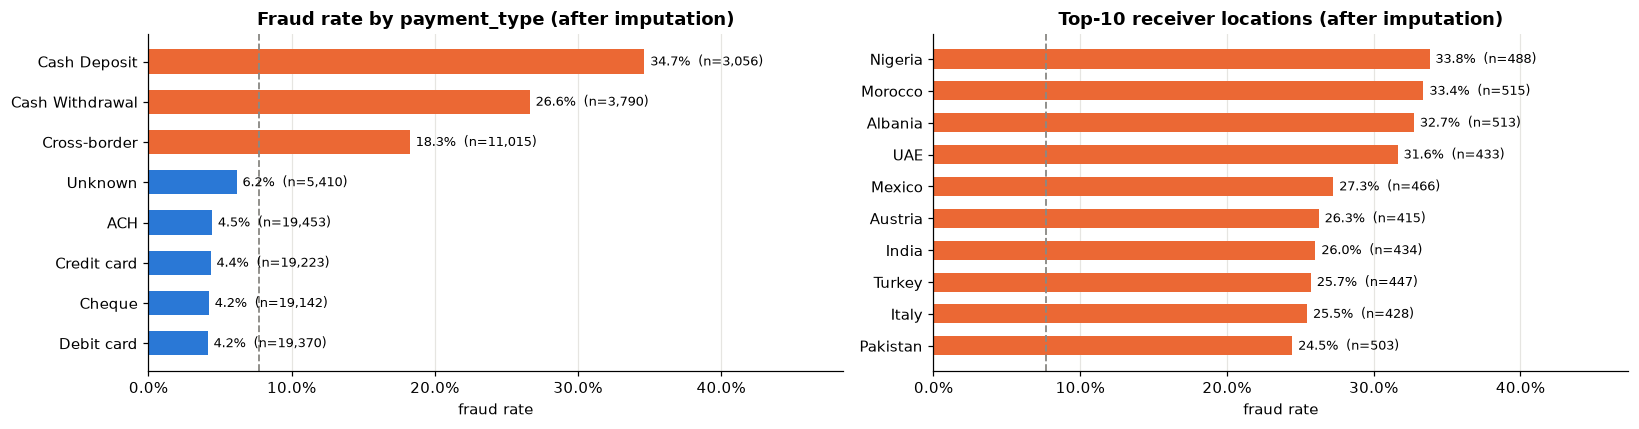

payment_type
ACH                19453
Debit card         19370
Credit card        19223
Cheque             19142
Cross-border       11015
Unknown             5410
Cash Withdrawal     3790
Cash Deposit        3056


In [37]:
# Sanity check: imputed payment types keep the expected risk profile
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
fraud_rate_plot(clean, "payment_type", ax=axes[0], title="Fraud rate by payment_type (after imputation)")
fraud_rate_plot(clean, "receiver_bank_location", ax=axes[1], top=10, title="Top-10 receiver locations (after imputation)")
plt.tight_layout(); plt.show()
print(clean.payment_type.value_counts().to_string())

In [38]:
clean.to_csv("FinTx-Guard_train_clean.csv", index=False)
print("Saved FinTx-Guard_train_clean.csv")

Saved FinTx-Guard_train_clean.csv


## 8. Summary of findings

**Data quality**
* 100,459 transactions, no duplicates, no invalid values. Seven columns have 3–10% missing values; missingness is not
  related to fraud, so rows are kept and imputed using domain rules (GBP ⇒ UK; different countries ⇒ Cross-border) or
  medians/`Unknown` categories.
* `amount` is extremely skewed and its outliers are highly fraudulent ⇒ log-transform, do not remove.
* Amounts appear to be on a common scale despite the "payment currency" description.

**What characterises suspicious transactions**
1. **Account-level behaviour is the strongest signal**: receivers with >10 incoming transactions (93% fraud), senders
   with >10 transactions (48%), and repeated transfers to the same counterpart (≥6 ⇒ 100%) — fan-in/fan-out mule
   patterns.
2. **Cash operations** (deposits 35%, withdrawals 27%) and **cross-border** payments (18%) are much riskier than
   card/ACH/cheque (~4%).
3. **International destinations and currency conversion** (21% vs 6%); highest risk for receivers in Nigeria, Morocco,
   Albania and the UAE (>30%), mainly on UK-originated corridors.
4. **Amount** has a non-monotonic effect: very small amounts, the 3k–4.8k band and especially the extreme tail
   (>99.9th percentile ⇒ 67% fraud).
5. **Time** has a small effect (early morning slightly riskier); stable over months except a rise in June 2023.
6. **Behavioural/device scores, channel and device recognition are essentially uninformative** on their own.

**Clustering** of sender accounts (K-Means, k = 7, label not used) recovers interpretable profiles whose fraud rates
range from 3.3% (small-amount domestic) to 35.8% (cash-oriented accounts), with inbound/outbound international
profiles at 15–17% — confirming the transaction-level findings. Extreme fan-out accounts are not isolated by
K-Means, so explicit account-level features remain necessary.

**Implications for Task 2 (predictive modelling)**: handle the 1:12 imbalance (stratification, class weights,
PR-AUC/F1), compute account aggregates without leakage (past-only windows, group-aware CV), prefer tree-based models
that capture the non-monotonic amount effect and categorical interactions, and consider dropping the uninformative
score features after validation.